# 06_09 Variance Reduction with CUPED (a short lesson)

**Learning objectives**
- Explain how a **pre-experiment covariate** reduces the noise of an A/B test without biasing it.
- Compute the **CUPED** adjustment $Y^*=Y-\theta(X-\bar X)$, the optimal $\theta$ and the variance reduction factor $1-\rho^2$.
- Quantify the **sample size saved** and avoid the main trap (adjusting for a post-treatment variable).

**Prerequisites:** [06_03 Hypothesis testing](06_03_hypothesis_testing_core.ipynb) (power and sample size), [06_07 A/B testing](06_07_ab_testing.ipynb), [03_01 Multivariate normal](../../module_03_multivariate/notebooks/03_01_multivariate_normal.ipynb) (correlation) (correlation).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
The standard error of a difference of two group means is $\sigma\sqrt{2/n}$; the sample size for power $1-\beta$ is $n=2(z_{1-\alpha/2}+z_{1-\beta})^2\sigma^2/\delta^2$ (06_03). Both depend on the **metric's variance $\sigma^2$**. If part of that variance is predictable from information available *before* the experiment, we can remove it.

## 3. Intuition and story
Revenue per user varies hugely between users, but a user who spent a lot last month will probably spend a lot this month. In an A/B test that between-user variation is **noise** that hides the small effect of the change. **CUPED** (Controlled-experiment Using Pre-Experiment Data) subtracts the part of each user's outcome that the user's own pre-experiment behaviour predicts. Randomisation guarantees the pre-experiment metric is balanced across groups, so the adjustment does not bias the comparison; it only removes noise. The result is the same answer with a narrower interval, or the same precision with fewer users.

## 4. Formal definitions
Let $Y$ be the experiment metric and $X$ a **pre-experiment** covariate (for example the same metric in the previous weeks). For a constant $\theta$ define
$$Y^*_i=Y_i-\theta\,(X_i-\bar X),\qquad \theta^*=\frac{\mathrm{Cov}(X,Y)}{\mathrm{Var}(X)}.$$
The difference of group means of $Y^*$ estimates the same treatment effect as that of $Y$. The **variance** is $\mathrm{Var}(Y^*)=\mathrm{Var}(Y)\,(1-\rho^2)$ at $\theta^*$, where $\rho=\mathrm{Corr}(X,Y)$.

## 5. Derivations
**Unbiasedness.** $E[X_i-\bar X]$ is the same in both groups because assignment is random and $X$ is measured before it. Hence $E[\bar Y^*_B-\bar Y^*_A]=E[\bar Y_B-\bar Y_A]-\theta\,E[\bar X_B-\bar X_A]=\delta-0=\delta$.

**Optimal $\theta$.** $\mathrm{Var}(Y-\theta X)=\sigma_Y^2-2\theta\,\mathrm{Cov}(X,Y)+\theta^2\sigma_X^2$ is a parabola in $\theta$ minimised at $\theta^*=\mathrm{Cov}(X,Y)/\sigma_X^2$, with minimum value $\sigma_Y^2-\mathrm{Cov}(X,Y)^2/\sigma_X^2=\sigma_Y^2(1-\rho^2)$. **In plain words.** CUPED is the regression of $Y$ on $X$; we keep only the residual, which is the part of $Y$ that $X$ cannot explain.

**Sample size.** Since $n\propto\sigma^2$, the sample size with CUPED is $n^*=n\,(1-\rho^2)$. A correlation of 0.7 halves the sample size; 0.9 cuts it by 81 %. **In plain words.** The better yesterday predicts today, the fewer users you need.

## 6. Properties and relationships
- Equivalent to **ANCOVA** (regression of $Y$ on treatment and $X$); with a balanced design they give the same estimate.
- Works best for metrics that are stable per user (revenue, sessions); little gain when $|\rho|$ is small. New users have no pre-period data.
- $X$ **must be measured before the assignment**. A covariate affected by the treatment biases the estimate.
- **Link to ML and AI:** the idea generalises to using a **model prediction** as the control variate (CUPAC): variance reduction in online experiments for ranking and recommender systems, and **control variates** in Monte Carlo (05_04).

## 7. 2D visuals

### 7.1 The adjustment
Left: outcome against the pre-period metric (strongly correlated). Right: the distribution of the metric before and after adjustment; the spread shrinks, the mean does not move.

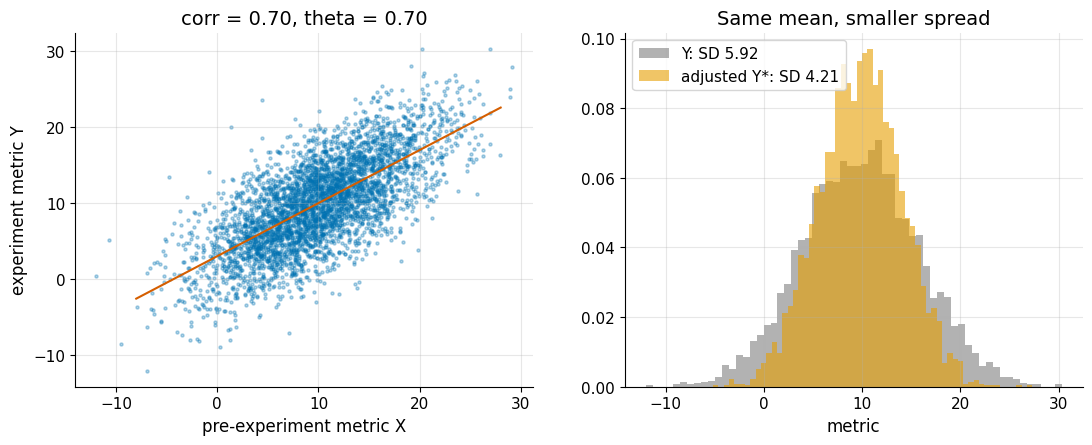

variance ratio 0.506 | theory 1 - rho^2 = 0.506


In [2]:
rng = np.random.default_rng(7); n = 4000; rho = 0.7; x = rng.normal(10, 6, n); y = 10 + rho * (x - 10) + np.sqrt(1 - rho ** 2) * rng.normal(0, 6, n)
theta = np.cov(x, y)[0, 1] / x.var(ddof=1); ystar = y - theta * (x - x.mean())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); axes[0].scatter(x, y, s=5, alpha=0.3, color=MAIN); axes[0].plot([-8, 28], [10 + theta * (-18), 10 + theta * 18], color=HIGHLIGHT); axes[0].set_xlabel("pre-experiment metric X"); axes[0].set_ylabel("experiment metric Y"); axes[0].set_title(f"corr = {np.corrcoef(x, y)[0, 1]:.2f}, theta = {theta:.2f}")
axes[1].hist(y, bins=60, alpha=0.5, color=NEUTRAL, density=True, label=f"Y: SD {y.std():.2f}"); axes[1].hist(ystar, bins=60, alpha=0.6, color=SIM, density=True, label=f"adjusted Y*: SD {ystar.std():.2f}"); axes[1].legend(); axes[1].set_xlabel("metric"); axes[1].set_title("Same mean, smaller spread")
plt.show()
print("variance ratio", round(ystar.var() / y.var(), 3), "| theory 1 - rho^2 =", round(1 - np.corrcoef(x, y)[0, 1] ** 2, 3))
assert abs(ystar.var() / y.var() - (1 - np.corrcoef(x, y)[0, 1] ** 2)) < 1e-3 and abs(ystar.mean() - y.mean()) < 1e-9

### 7.2 Sample size saved
Required sample size per group for a lift of 0.5 (metric SD 6, 80 % power) against the correlation.

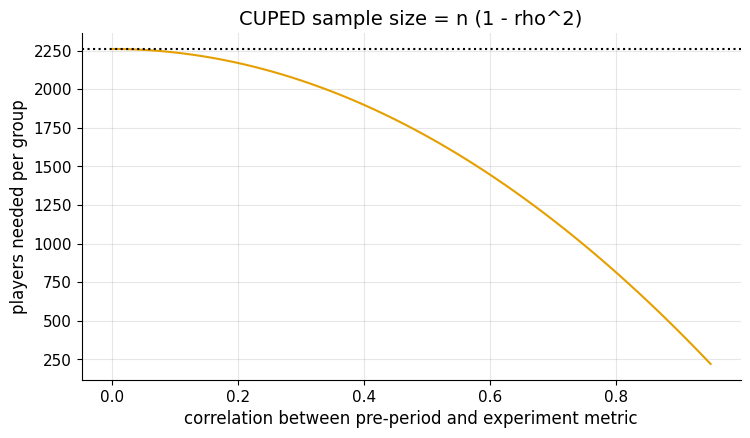

n without CUPED: 2261 | at rho 0.5, 0.7, 0.9: [1695, 1153, 429]


In [3]:
rg = np.linspace(0, 0.95, 100); n0 = 2 * (1.96 + 0.8416) ** 2 * 36 / 0.25; fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(rg, n0 * (1 - rg ** 2), color=SIM); ax.axhline(n0, color="black", linestyle=":"); ax.set_xlabel("correlation between pre-period and experiment metric"); ax.set_ylabel("players needed per group"); ax.set_title("CUPED sample size = n (1 - rho^2)")
plt.show(); print("n without CUPED:", round(n0), "| at rho 0.5, 0.7, 0.9:", [round(n0 * (1 - r ** 2)) for r in (0.5, 0.7, 0.9)])
assert 2250 < n0 < 2270

## 8. 3D visuals

### 8.1 Static: required sample size over (correlation, effect size)
The sample size grows as $1/\delta^2$ and shrinks by $1-\rho^2$.

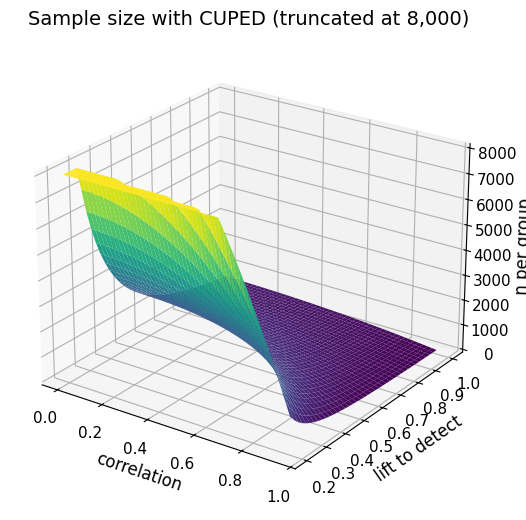

In [4]:
rr_ = np.linspace(0, 0.95, 50); dd = np.linspace(0.2, 1.0, 40); Rg, Dg = np.meshgrid(rr_, dd); NN = 2 * (1.96 + 0.8416) ** 2 * 36 * (1 - Rg ** 2) / Dg ** 2
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(Rg, Dg, np.minimum(NN, 8000), cmap="viridis", edgecolor="none"); ax.set_xlabel("correlation"); ax.set_ylabel("lift to detect"); ax.set_zlabel("n per group"); ax.set_title("Sample size with CUPED (truncated at 8,000)"); ax.view_init(elev=24, azim=-55)
plt.show()

### 8.2 Interactive Plotly version of 8.1

In [5]:
fig = go.Figure(go.Surface(x=rr_, y=dd, z=np.minimum(NN, 8000), colorscale="Viridis")); fig.update_layout(title="Sample size per group", width=760, height=560, scene=dict(xaxis_title="correlation", yaxis_title="lift", zaxis_title="n")); fig.show()

## 9. Simulation vs theory
Run 3,000 experiments with a true lift of 0.5 and correlation 0.7. CUPED should be unbiased, its standard deviation should shrink by $\sqrt{1-\rho^2}=0.714$, and the power should rise.

In [6]:
def experiment(n=1000, lift=0.5, rho=0.7, g=None):
    x = g.normal(10, 6, 2 * n); t = np.repeat([0, 1], n); y = 10 + rho * (x - 10) + np.sqrt(1 - rho ** 2) * g.normal(0, 6, 2 * n) + lift * t
    th = np.cov(x, y)[0, 1] / x.var(ddof=1); ys = y - th * (x - x.mean()); d0 = y[t == 1].mean() - y[t == 0].mean(); d1 = ys[t == 1].mean() - ys[t == 0].mean()
    s0 = np.sqrt(y[t == 1].var(ddof=1) / n + y[t == 0].var(ddof=1) / n); s1 = np.sqrt(ys[t == 1].var(ddof=1) / n + ys[t == 0].var(ddof=1) / n); return d0, d1, s0, s1
g = np.random.default_rng(10); res = np.array([experiment(g=g) for _ in range(3000)]); d0, d1, s0, s1 = res.T
print(f"mean estimate: plain {d0.mean():.4f}, CUPED {d1.mean():.4f} (true 0.5) | SD of estimate: plain {d0.std():.4f}, CUPED {d1.std():.4f}, ratio {d1.std() / d0.std():.3f} (theory {np.sqrt(1 - 0.49):.3f})")
print(f"power: plain {np.mean(np.abs(d0 / s0) > 1.96):.3f}, CUPED {np.mean(np.abs(d1 / s1) > 1.96):.3f}")
assert abs(d1.mean() - 0.5) < 0.01 and abs(d1.std() / d0.std() - 0.714) < 0.03 and np.mean(np.abs(d1 / s1) > 1.96) > np.mean(np.abs(d0 / s0) > 1.96) + 0.1

mean estimate: plain 0.5072, CUPED 0.5007 (true 0.5) | SD of estimate: plain 0.2673, CUPED 0.1910, ratio 0.715 (theory 0.714)
power: plain 0.472, CUPED 0.758


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [7]:
print("theta = np.cov(x, y)[0, 1] / x.var(ddof=1) ->", round(theta, 4), "| equals the OLS slope: stats.linregress(x, y).slope ->", round(stats.linregress(x, y).slope, 4))
print("adjusted metric: y - theta * (x - x.mean()); variance ratio:", round(ystar.var() / y.var(), 3))
print("difference test on the adjusted metric: stats.ttest_ind(ystar[t == 1], ystar[t == 0], equal_var=False)")
print("sample size: 2 * (1.96 + 0.8416) ** 2 * sigma ** 2 * (1 - rho ** 2) / delta ** 2 ->", round(2 * (1.96 + 0.8416) ** 2 * 36 * 0.51 / 0.25))

theta = np.cov(x, y)[0, 1] / x.var(ddof=1) -> 0.6989 | equals the OLS slope: stats.linregress(x, y).slope -> 0.6989
adjusted metric: y - theta * (x - x.mean()); variance ratio: 0.506
difference test on the adjusted metric: stats.ttest_ind(ystar[t == 1], ystar[t == 0], equal_var=False)
sample size: 2 * (1.96 + 0.8416) ** 2 * sigma ** 2 * (1 - rho ** 2) / delta ** 2 -> 1153


## 11. Real-world worked examples

---
### Example 1 (main): a revenue experiment with last month's spend as the covariate
**Scenario.** 2,000 users per group; revenue per user has SD 6 dollars; the correlation between last month's and this month's spend is 0.7; the new checkout adds 0.5 dollars per user on average.

**Questions**
1. What are the standard errors of the difference without and with CUPED?
2. How many users per group would be needed to detect 0.5 dollars with 80 % power, without and with CUPED?
3. Run one simulated experiment and compare the two analyses.

### 11.1 By hand
**Q1.** $\mathrm{SE}=\sigma\sqrt{2/n}=6\sqrt{2/2000}=0.190$; with CUPED $0.190\sqrt{1-0.49}=0.136$. **Q2.** $n=2(2.8016)^2(36)/0.25=2{,}261$ per group; with CUPED $2{,}261\times0.51=1{,}153$. **Q3.** below.

In [8]:
se0 = 6 * np.sqrt(2 / 2000); se1 = se0 * np.sqrt(1 - 0.7 ** 2); n_plain = 2 * (1.96 + 0.8416) ** 2 * 36 / 0.25; n_cuped = n_plain * (1 - 0.49)
g = np.random.default_rng(21); d0_, d1_, s0_, s1_ = experiment(n=2000, g=g)
print(f"Q1: SE plain {se0:.4f}, SE CUPED {se1:.4f} | Q2: n plain {n_plain:.0f}, n CUPED {n_cuped:.0f}")
print(f"Q3: plain estimate {d0_:.3f} (SE {s0_:.3f}, z = {d0_ / s0_:.2f}) | CUPED estimate {d1_:.3f} (SE {s1_:.3f}, z = {d1_ / s1_:.2f})")

Q1: SE plain 0.1897, SE CUPED 0.1355 | Q2: n plain 2261, n CUPED 1153
Q3: plain estimate 0.469 (SE 0.187, z = 2.51) | CUPED estimate 0.657 (SE 0.136, z = 4.83)


### 11.2 In code with `scipy`, and the asserts

In [9]:
assert abs(se0 - 0.1897) < 1e-3 and abs(se1 - 0.1355) < 1e-3 and round(n_plain) == 2261 and round(n_cuped) == 1153 and abs(s1_ / s0_ - 0.714) < 0.03
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
The standard errors reported by the analysis match the real spread of the estimates over 3,000 repetitions (section 9): the mean reported SE should be close to the SD of the estimates.

In [10]:
print(f"plain: mean SE {s0.mean():.4f} vs SD of estimates {d0.std():.4f} | CUPED: mean SE {s1.mean():.4f} vs SD {d1.std():.4f}")
assert abs(s1.mean() / d1.std() - 1) < 0.04 and abs(s0.mean() / d0.std() - 1) < 0.04

plain: mean SE 0.2682 vs SD of estimates 0.2673 | CUPED: mean SE 0.1915 vs SD 0.1910


### 11.4 Plots with the regions shaded

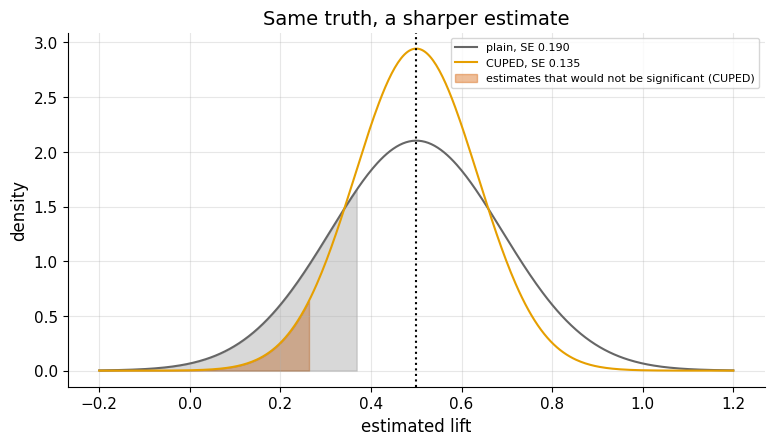

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.6)); xs = np.linspace(-0.2, 1.2, 400)
ax.plot(xs, stats.norm.pdf(xs, 0.5, se0), color=NEUTRAL, label=f"plain, SE {se0:.3f}"); ax.plot(xs, stats.norm.pdf(xs, 0.5, se1), color=SIM, label=f"CUPED, SE {se1:.3f}"); ax.fill_between(xs, stats.norm.pdf(xs, 0.5, se1), where=xs <= 0.0 + 1.96 * se1, color=HIGHLIGHT, alpha=0.4, label="estimates that would not be significant (CUPED)"); ax.fill_between(xs, stats.norm.pdf(xs, 0.5, se0), where=xs <= 1.96 * se0, color=NEUTRAL, alpha=0.25)
ax.axvline(0.5, color="black", linestyle=":"); ax.set_xlabel("estimated lift"); ax.set_ylabel("density"); ax.set_title("Same truth, a sharper estimate"); ax.legend(fontsize=8)
plt.show()

### 11.5 Interpretation and decision (Example 1)
- The standard error of the lift drops from **0.190 to 0.136 dollars**, a factor $\sqrt{1-\rho^2}=0.714$, and the sample size needed for 80 % power from **2,261 to 1,153 per group**.
- In the single simulated experiment the plain analysis gives a lift of 0.469 (z = 2.51) and the CUPED analysis 0.657 (z = 4.83): the estimates differ only because noise was removed; over 3,000 repetitions both are unbiased (CUPED mean 0.50), the estimate's SD falls from 0.267 to 0.191 and the power at 1,000 per group rises from **47 % to 76 %**. The standard errors reported by the analysis (0.268 and 0.192) match the real spread of the estimates.
- **Decision.** Use the pre-period spend as a CUPED covariate in every revenue test; it is free, unbiased, and equivalent to nearly doubling the sample size at $\rho=0.7$. Fix the covariate and the model before looking at the results.

---
### Example 2: how much does the correlation matter?
**Scenario.** Three metrics: a stable one ($\rho=0.9$, spend), a medium one ($\rho=0.5$, sessions) and a weak one ($\rho=0.2$, clicks on a new feature).

**Questions.** (1) Sample size per group for a lift of 0.5 with SD 6 for each, with CUPED. (2) By simulation, the SD reduction of the estimate for each.

     n per group with CUPED  saving  SD ratio simulated  theory sqrt(1 - rho^2)
rho                                                                            
0.9                     429    0.81               0.436                   0.436
0.5                    1695    0.25               0.864                   0.866
0.2                    2170    0.04               0.978                   0.980


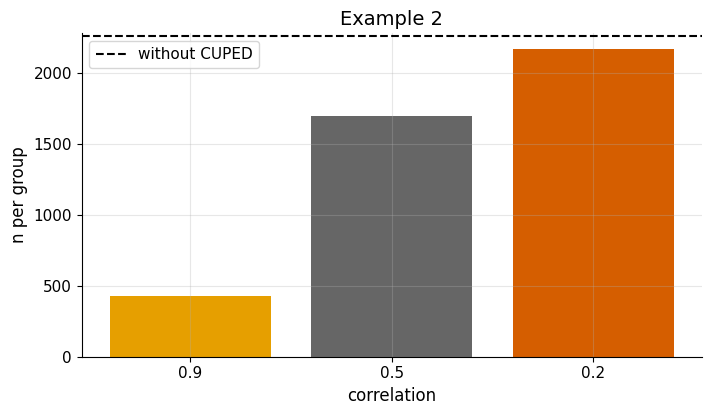

In [12]:
g = np.random.default_rng(31); rows = []
for r_ in (0.9, 0.5, 0.2):
    out = np.array([experiment(n=500, rho=r_, g=g)[:2] for _ in range(1500)]); rows.append({"rho": r_, "n per group with CUPED": round(n_plain * (1 - r_ ** 2)), "saving": 1 - (1 - r_ ** 2), "SD ratio simulated": out[:, 1].std() / out[:, 0].std(), "theory sqrt(1 - rho^2)": np.sqrt(1 - r_ ** 2)})
tab = pd.DataFrame(rows).set_index("rho"); print(tab.round(3).to_string())
assert np.allclose(tab["SD ratio simulated"], tab["theory sqrt(1 - rho^2)"], atol=0.04)
fig, ax = plt.subplots(figsize=(8, 4.2)); ax.bar([str(r) for r in tab.index], tab["n per group with CUPED"], color=[SIM, NEUTRAL, HIGHLIGHT]); ax.axhline(n_plain, color="black", linestyle="--", label="without CUPED"); ax.set_xlabel("correlation"); ax.set_ylabel("n per group"); ax.legend(); ax.set_title("Example 2")
plt.show()

### 11.7 Interpretation and decision (Example 2)
- With $\rho=0.9$ the sample size falls from 2,261 to **429** per group (81 % saved); with $\rho=0.5$ to **1,695** (25 %); with $\rho=0.2$ only to **2,170** (4 %). The simulated SD ratios (0.436, 0.864, 0.978) match $\sqrt{1-\rho^2}$.
- **Decision.** Spend on variance reduction where the user's own history predicts the outcome (revenue, sessions); do not expect help for a brand-new feature with no history.

---
### Example 3: the trap of a post-treatment covariate
**Scenario.** The new checkout also increases the number of items viewed *during* the experiment. An analyst adjusts the revenue for "items viewed in the experiment" (a variable affected by the treatment).

**Questions.** Compare the adjustment with the pre-period covariate and with the post-treatment covariate in terms of bias (true lift 0.5).

true total lift of revenue: 0.5 | pre-period CUPED mean estimate: 0.506 | post-treatment adjusted mean estimate: -2.276


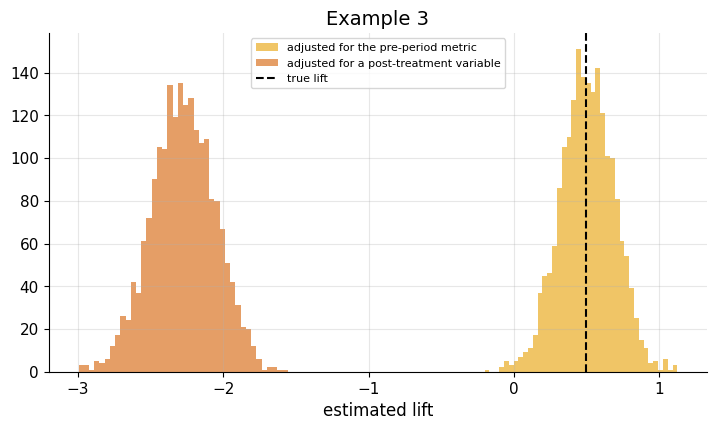

In [13]:
g = np.random.default_rng(41); est_pre, est_post = [], []
for _ in range(2000):
    n_ = 1000; t = np.repeat([0, 1], n_); pre = g.normal(10, 6, 2 * n_); views = 5 + 0.3 * (pre - 10) + 2.0 * t + g.normal(0, 2, 2 * n_); y = 10 + 0.7 * (pre - 10) + 0.5 * views + g.normal(0, 4, 2 * n_) + (0.5 - 0.5 * 2.0) * t
    for xcov, store in ((pre, est_pre), (views, est_post)):
        th = np.cov(xcov, y)[0, 1] / xcov.var(ddof=1); ys = y - th * (xcov - xcov.mean()); store.append(ys[t == 1].mean() - ys[t == 0].mean())
print("true total lift of revenue:", 0.5, "| pre-period CUPED mean estimate:", round(np.mean(est_pre), 3), "| post-treatment adjusted mean estimate:", round(np.mean(est_post), 3))
assert abs(np.mean(est_pre) - 0.5) < 0.05 and abs(np.mean(est_post) - 0.5) > 0.3
fig, ax = plt.subplots(figsize=(8.5, 4.4)); ax.hist(est_pre, bins=40, alpha=0.6, color=SIM, label="adjusted for the pre-period metric"); ax.hist(est_post, bins=40, alpha=0.6, color=HIGHLIGHT, label="adjusted for a post-treatment variable"); ax.axvline(0.5, color="black", linestyle="--", label="true lift"); ax.legend(fontsize=8); ax.set_xlabel("estimated lift"); ax.set_title("Example 3")
plt.show()

### 11.9 Interpretation and decision (Example 3)
- Adjusting for the **pre-period** metric recovers the true lift (mean estimate **0.506** against 0.5). Adjusting for **items viewed during the experiment**, a variable the treatment itself moves, gives a mean estimate of **-2.28**: biased, and even of the wrong sign, because part of the real effect travels through that variable.
- **Decision.** Use only covariates fixed before the assignment (the pre-period metric, country, device); never adjust for outcomes or mediators measured after the treatment starts.

## 12. Where it is used
- **Statistics:** ANCOVA, control variates, regression adjustment in randomised trials.
- **Data science:** standard in online experimentation platforms to detect small lifts with fewer users; also stratification and post-stratification.
- **ML and AI:** CUPAC uses a model prediction as the covariate; control variates reduce variance in Monte Carlo and in off-policy evaluation of recommenders.

## 13. Common pitfalls and misconceptions
- **Using a covariate measured after the assignment** (Example 3) biases the effect.
- **Expecting a gain when $\rho$ is small:** the variance falls by $\rho^2$ only.
- **Estimating $\theta$ separately in each group** is fine but must be done consistently; use the pooled estimate.
- **Users without pre-period data:** impute the mean and add an indicator, or analyse them separately.
- **CUPED does not fix a biased or broken randomisation.**

## 14. Exercises
1. For $\rho=0.6$, by what fraction does CUPED reduce the variance and the sample size?
2. $\mathrm{Cov}(X,Y)=18$, $\mathrm{Var}(X)=36$, $\mathrm{Var}(Y)=64$: find $\theta^*$, $\rho$ and the adjusted variance.
3. A test needs 10,000 users per group. With a pre-period correlation of 0.8, how many are needed with CUPED?
4. Simulate that CUPED keeps the 5 % false-positive rate in an A/A test (correlation 0.7).
5. (Harder) The treatment raises a covariate $V$ by 2 units, and revenue depends on $V$ (0.5 per unit) and directly on the treatment (0 or 0.5). Simulate the estimate adjusted for $V$ and compare it with the total effect.

Solutions are at the end.

## 15. Summary table

| Item | Formula | Note |
|---|---|---|
| Adjusted metric | $Y-\theta(X-\bar X)$ | $X$ measured before the assignment |
| Optimal $\theta$ | $\mathrm{Cov}(X,Y)/\mathrm{Var}(X)$ | OLS slope |
| Variance | $(1-\rho^2)\sigma^2$ | |
| Sample size | $n(1-\rho^2)$ | $\rho=0.7$ halves it |
| scipy | `np.cov`, `stats.linregress` | |

## Solutions

In [14]:
print("1: variance and sample size fall by", 1 - (1 - 0.36), "-> 36%")
print("2: theta =", 18 / 36, "| rho =", round(18 / np.sqrt(36 * 64), 4), "| adjusted variance =", 64 * (1 - (18 / np.sqrt(36 * 64)) ** 2), "(= 64 - 18^2/36 = 55)")
print("3: n =", 10000 * (1 - 0.64))
g = np.random.default_rng(5); rs_ = np.array([experiment(n=1000, lift=0.0, g=g) for _ in range(1500)]); fp = np.mean(np.abs(rs_[:, 1] / rs_[:, 3]) > 1.96); print("4: false-positive rate of CUPED in A/A tests:", round(fp, 4))
g = np.random.default_rng(6); z0, z1 = [], []
for eff in (0.0, 0.5):
    est = []
    for _ in range(1000):
        n_ = 1000; t = np.repeat([0, 1], n_); v = 5 + 2 * t + g.normal(0, 2, 2 * n_); y = 10 + 0.5 * v + eff * t + g.normal(0, 4, 2 * n_); th = np.cov(v, y)[0, 1] / v.var(ddof=1); ys = y - th * (v - v.mean()); est.append(ys[t == 1].mean() - ys[t == 0].mean())
    print(f"5: true direct effect {eff}: mean adjusted estimate {np.mean(est):.3f} (the pathway through the covariate is removed, so the total effect {eff + 1.0} is missed)")
assert 0.03 < fp < 0.07

1: variance and sample size fall by 0.36 -> 36%
2: theta = 0.5 | rho = 0.375 | adjusted variance = 55.0 (= 64 - 18^2/36 = 55)
3: n = 3600.0


4: false-positive rate of CUPED in A/A tests: 0.0527


5: true direct effect 0.0: mean adjusted estimate -0.002 (the pathway through the covariate is removed, so the total effect 1.0 is missed)


5: true direct effect 0.5: mean adjusted estimate 0.400 (the pathway through the covariate is removed, so the total effect 1.5 is missed)


**1.** $1-\rho^2=0.64$: the variance and the sample size fall by **36 %**.

**2.** $\theta^*=18/36=0.5$, $\rho=18/\sqrt{36\times64}=0.375$, adjusted variance $64-18^2/36=\,$**55** (a reduction of 14 %).

**3.** $10{,}000\times(1-0.64)=$ **3,600** per group.

**4.** The CUPED false-positive rate in 1,500 A/A tests is **5.3 %**: nominal level kept.

**5.** When the direct effect is 0 the adjusted estimate is about **0.00**, although the total effect is $0.5\times2=1.0$ (the whole effect goes through $V$ and is adjusted away); when the direct effect is 0.5 the adjusted estimate is **0.40**, not the total effect 1.5. Adjusting for a post-treatment variable answers a different question (the effect that does *not* go through $V$) and is not a variance reduction.